# Análisis numérico — Modelado térmico de un centro de datos para DeepSeek

**Proyecto:** Optimización energética y modelado térmico de un centro de datos para el despliegue mínimo óptimo de DeepSeek
**Autores:** Takeshi Tatekawa, Diego Bedoya, Juan David Penagos, Samuel Sepulveda, Joe Sarria, Johnny Portilla — Universidad Icesi

Este cuaderno documenta y justifica **todo el análisis numérico** del proyecto: el modelo, la solución analítica, los métodos de **Euler** y **Runge-Kutta 4 programados a mano** (sin `scipy.integrate`), su validación, el análisis de errores y convergencia, la estabilidad, el costo computacional, la verificación en el caso no lineal, la conservación de la energía, la sensibilidad paramétrica y la comparación teórico–numérica.

**Cómo usarlo:** menú *Entorno de ejecución → Ejecutar todo*. Todo el código está en este cuaderno; no necesita archivos externos. La ejecución completa tarda alrededor de un minuto.

**Contenido**
1. Modelo matemático y parámetros
2. Métodos numéricos: Euler y RK4
3. Solución analítica
4. Validación frente a la solución analítica
5. Errores absoluto y relativo para distintos pasos
6. Orden de convergencia
7. Estabilidad de Euler
8. Costo computacional frente a precisión
9. Caso general sin solución analítica (solución de referencia)
10. Escenarios E1–E5 y conservación de la energía
11. Sensibilidad paramétrica
12. Comparación teórico–numérica
13. Conclusiones del análisis numérico

## 1. Modelo matemático y parámetros

La sala de servidores se modela como **un solo nodo térmico** (aire bien mezclado) de capacidad térmica $C$ y temperatura $T(t)$. Por conservación de la energía (primera ley de la termodinámica):

$$C\,\frac{dT}{dt} = P_s(t) - hA\,\big[T - T_a(t)\big] - Q_{ref}(T)$$

- Potencia térmica de los servidores (modelo de Fan, Weber y Barroso): $P_s(u) = N\,P_{max}\,[k_{idle} + (1-k_{idle})\,u]$
- Refrigeración con control proporcional saturado: $Q_{ref} = \min\{\max[K_p(T - T_{set}),\,0],\,Q_{max}\}$
- Energía eléctrica de refrigeración: $P_{cool} = Q_{ref}/\mathrm{COP}(T_a)$; eficiencia: $\mathrm{PUE} = P_{total}/P_{IT}$
- Condición inicial: $T(0) = T_0$

**Análisis dimensional:** $[C][dT/dt] = (\mathrm{J/K})(\mathrm{K/s}) = \mathrm{W}$, igual que cada término del lado derecho.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass

# Compatibilidad NumPy 1.x / 2.x
trapezoid = getattr(np, "trapezoid", None) or np.trapz

# Estilo de las gráficas
C1, C2, C3, C4, C5 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
GRIS, CRIT = "#52514e", "#b3261e"
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.grid": True,
    "grid.color": "#e5e4e0", "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
print("NumPy", np.__version__, "| pandas", pd.__version__)

NumPy 2.5.3 | pandas 3.0.5


In [2]:
@dataclass
class Params:
    N_serv: int = 2              # nodos DGX H100 [-]
    P_nodo_max: float = 10_200.0 # potencia máxima por nodo [W] (NVIDIA)
    k_idle: float = 0.30         # fracción de potencia en reposo [-]
    f_aux: float = 0.05          # auxiliares eléctricos [-]
    C: float = 2.0e6             # capacidad térmica equivalente [J/K]
    hA: float = 250.0            # disipación pasiva global [W/K]
    T_set: float = 24.0          # consigna [°C]
    Kp: float = 2_500.0          # ganancia proporcional [W/K]
    f_dim: float = 1.2           # sobredimensionamiento de Q_max [-]
    estrategia: str = "aire"     # 'aire', 'liquida' o 'free'
    T_alerta: float = 27.0       # límite recomendado ASHRAE [°C]
    T_critica: float = 32.0      # límite admisible clase A1 [°C]

    @property
    def P_IT_max(self): return self.N_serv * self.P_nodo_max
    @property
    def Q_max(self): return self.f_dim * self.P_IT_max

def P_IT(u, p):
    # Potencia de los servidores [W]: modelo lineal reposo-pico
    u = np.clip(u, 0.0, 1.0)
    return p.N_serv * p.P_nodo_max * (p.k_idle + (1.0 - p.k_idle) * u)

def COP(T_a, p):
    # Coeficiente de desempeño de la refrigeración según la estrategia
    T_a = np.asarray(T_a, dtype=float)
    aire = np.maximum(1.8, 4.0 - 0.08 * (T_a - 20.0))
    if p.estrategia == "aire":
        return aire
    if p.estrategia == "liquida":
        return np.maximum(3.0, 7.0 - 0.05 * (T_a - 20.0))
    if p.estrategia == "free":
        return np.where(T_a < p.T_set - 4.0, 15.0, aire)
    raise ValueError(p.estrategia)

def Q_ref_control(T, p):
    # Control proporcional saturado [W]
    return np.clip(p.Kp * (np.asarray(T) - p.T_set), 0.0, p.Q_max)

def dTdt(t, T, p, u_fun, Ta_fun):
    # Lado derecho de la EDO: dT/dt = (P_s - hA(T - T_a) - Q_ref) / C
    Ps = P_IT(u_fun(t), p)
    Qr = Q_ref_control(T, p)
    return (Ps - p.hA * (T - Ta_fun(t)) - Qr) / p.C

def perfil_Ta(T_media, amplitud):
    # Ciclo diurno sinusoidal con máximo a las 15:00
    return lambda t: T_media + amplitud * np.sin(2*np.pi*(t/86400.0) - 2*np.pi*9/24)

def perfil_carga(u_base, amp_diurna=0.20, amp_rafagas=0.10):
    # Carga de inferencia: ciclo laboral + ráfagas deterministas de tokens
    def u(t):
        h = t / 3600.0
        diurno = amp_diurna * np.sin(2*np.pi*(h - 8.0)/24.0)
        rafaga = amp_rafagas * (0.6*np.sin(2*np.pi*h/1.7) + 0.4*np.sin(2*np.pi*h/0.45 + 1.3))
        return float(np.clip(u_base + diurno + rafaga, 0.05, 1.0))
    return u

p0 = Params()
pd.DataFrame({
    "Parámetro": ["N", "P_max por nodo", "k_idle", "C", "hA", "T_set", "K_p", "Q_max"],
    "Valor": [p0.N_serv, p0.P_nodo_max, p0.k_idle, p0.C, p0.hA, p0.T_set, p0.Kp, p0.Q_max],
    "Unidad": ["-", "W", "-", "J/K", "W/K", "°C", "W/K", "W"],
})

,Parámetro,Valor,Unidad
0,N,2,-
1,P_max por nodo,1.02e+04,W
2,k_idle,0.3,-
3,C,2e+06,J/K
4,hA,250,W/K
5,T_set,24,°C
6,K_p,2500,W/K
7,Q_max,2.448e+04,W


## 2. Métodos numéricos: Euler y RK4 (programados a mano)

Para una EDO $dT/dt = f(t, T)$ con paso $\Delta t$:

**Euler explícito (orden 1):**
$$T_{n+1} = T_n + \Delta t\, f(t_n, T_n)$$

**Runge-Kutta clásico de 4.º orden (orden 4):**
$$k_1 = f(t_n, T_n),\quad k_2 = f\!\left(t_n + \tfrac{\Delta t}{2},\, T_n + \tfrac{\Delta t}{2}k_1\right),\quad k_3 = f\!\left(t_n + \tfrac{\Delta t}{2},\, T_n + \tfrac{\Delta t}{2}k_2\right),\quad k_4 = f(t_n + \Delta t,\, T_n + \Delta t\,k_3)$$
$$T_{n+1} = T_n + \frac{\Delta t}{6}\,(k_1 + 2k_2 + 2k_3 + k_4)$$

Euler usa solo la pendiente al inicio del paso; RK4 combina cuatro pendientes (inicio, dos a mitad de paso y final), lo que cancela los términos de error hasta $\Delta t^4$.

In [3]:
def euler(f, t0, tf, T0, dt, *args):
    n = int(round((tf - t0) / dt))
    t = t0 + dt * np.arange(n + 1)
    T = np.empty(n + 1); T[0] = T0
    for k in range(n):
        T[k + 1] = T[k] + dt * f(t[k], T[k], *args)
    return t, T

def rk4(f, t0, tf, T0, dt, *args):
    n = int(round((tf - t0) / dt))
    t = t0 + dt * np.arange(n + 1)
    T = np.empty(n + 1); T[0] = T0
    for k in range(n):
        k1 = f(t[k],          T[k],               *args)
        k2 = f(t[k] + dt / 2, T[k] + dt * k1 / 2, *args)
        k3 = f(t[k] + dt / 2, T[k] + dt * k2 / 2, *args)
        k4 = f(t[k] + dt,     T[k] + dt * k3,     *args)
        T[k + 1] = T[k] + dt * (k1 + 2*k2 + 2*k3 + k4) / 6.0
    return t, T

def simular(p, u_fun, Ta_fun, T0=22.0, tf=24*3600.0, dt=10.0, metodo="rk4"):
    integrador = rk4 if metodo == "rk4" else euler
    t, T = integrador(dTdt, 0.0, tf, T0, dt, p, u_fun, Ta_fun)
    u = np.clip(np.vectorize(u_fun)(t), 0, 1)
    Ta = np.vectorize(Ta_fun)(t)
    Ps = P_IT(u, p); Qr = Q_ref_control(T, p); cop = COP(Ta, p)
    P_cool = Qr / cop
    P_aux = p.f_aux * p.P_IT_max * np.ones_like(t)
    P_tot = Ps + P_cool + P_aux
    E = lambda y: np.concatenate(([0.0], np.cumsum(0.5*(y[1:] + y[:-1])*np.diff(t))))
    # Balance de energía: ∫P_s dt = C·ΔT + ∫hA(T−T_a) dt + ∫Q_ref dt + residuo
    E_in, E_env, E_ref = E(Ps)[-1], E(p.hA*(T - Ta))[-1], E(Qr)[-1]
    dU = p.C * (T[-1] - T[0])
    res = E_in - (dU + E_env + E_ref)
    return dict(t=t, T=T, Ta=Ta, Ps=Ps, Qr=Qr, COP=cop, P_cool=P_cool, P_tot=P_tot,
                PUE=P_tot/Ps, E_IT=E(Ps), E_cool=E(P_cool), E_tot=E(P_tot),
                balance=dict(E_in=E_in, dU=dU, E_env=E_env, E_ref=E_ref,
                             residuo=res, residuo_rel=abs(res)/E_in),
                frac_alerta=float(np.mean(T > p.T_alerta)),
                frac_critica=float(np.mean(T > p.T_critica)))
print("Integradores y simulador definidos.")

Integradores y simulador definidos.


## 3. Solución analítica

Con $P_s$, $T_a$ y $Q_{ref}$ constantes la EDO es lineal de primer orden y su solución es una relajación exponencial:

$$T(t) = T_{ss} + (T_0 - T_{ss})\,e^{-t/\tau}$$

- **Lazo abierto** (sin control): $\tau = C/hA$, $\;T_{ss} = T_a + (P_s - Q_{ref})/hA$
- **Lazo cerrado sin saturar** ($0 < K_p(T - T_{set}) < Q_{max}$): $\tau_{cl} = C/(hA + K_p)$, $\;T_{ss} = \dfrac{P_s + hA\,T_a + K_p\,T_{set}}{hA + K_p}$

Esta solución exacta es el **patrón de referencia** para validar Euler y RK4.

P_s pico = 20400 W
Lazo abierto : tau = 8000 s (2.22 h) | T_ss = 101.6 °C (si falla la refrigeración)
Lazo cerrado : tau = 727.3 s (12.1 min) | T_ss = 31.05 °C
Q_ref en estado estacionario = 17636 W < Q_max = 24480 W -> control no saturado


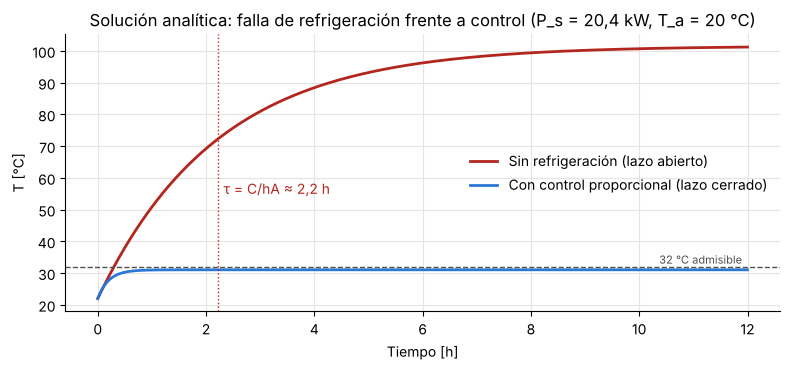

In [4]:
def analitica(t, T0, Tss, tau):
    return Tss + (T0 - Tss) * np.exp(-np.asarray(t) / tau)

Ps_pico, Ta_cte = P_IT(1.0, p0), 20.0
tau_oa = p0.C / p0.hA
Tss_oa = Ta_cte + Ps_pico / p0.hA                       # falla de la refrigeración (Q_ref = 0)
tau_cl = p0.C / (p0.hA + p0.Kp)
Tss_cl = (Ps_pico + p0.hA*Ta_cte + p0.Kp*p0.T_set) / (p0.hA + p0.Kp)
Qr_ss = p0.Kp * (Tss_cl - p0.T_set)

print(f"P_s pico = {Ps_pico:.0f} W")
print(f"Lazo abierto : tau = {tau_oa:.0f} s ({tau_oa/3600:.2f} h) | T_ss = {Tss_oa:.1f} °C (si falla la refrigeración)")
print(f"Lazo cerrado : tau = {tau_cl:.1f} s ({tau_cl/60:.1f} min) | T_ss = {Tss_cl:.2f} °C")
print(f"Q_ref en estado estacionario = {Qr_ss:.0f} W < Q_max = {p0.Q_max:.0f} W -> control no saturado")

t = np.linspace(0, 12*3600, 600)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(t/3600, analitica(t, 22, Tss_oa, tau_oa), color=CRIT, lw=2, label="Sin refrigeración (lazo abierto)")
ax.plot(t/3600, analitica(t, 22, Tss_cl, tau_cl), color=C1, lw=2, label="Con control proporcional (lazo cerrado)")
ax.axvline(tau_oa/3600, color=CRIT, ls=":", lw=1); ax.text(tau_oa/3600 + 0.1, 55, "τ = C/hA ≈ 2,2 h", color=CRIT)
ax.axhline(32, color=GRIS, ls="--", lw=1); ax.text(11.9, 33, "32 °C admisible", ha="right", color=GRIS, fontsize=8)
ax.set_xlabel("Tiempo [h]"); ax.set_ylabel("T [°C]")
ax.set_title("Solución analítica: falla de refrigeración frente a control (P_s = 20,4 kW, T_a = 20 °C)")
ax.legend(frameon=False); fig.tight_layout(); plt.show()

## 4. Validación frente a la solución analítica

Caso de prueba lineal: carga máxima $u = 1$, $T_a = 20\,°C$ constante y $T_0 = 25\,°C > T_{set}$, de modo que el control **nunca se satura** y la solución exacta es la de lazo cerrado. Se integra 2 h ($\approx 10\,\tau_{cl}$) con un paso deliberadamente grueso, $\Delta t = 300$ s $\approx 0{,}4\,\tau_{cl}$, para que las diferencias se vean.

Error máximo con Δt = 300 s -> Euler: 5.635e-01 °C | RK4: 7.461e-04 °C


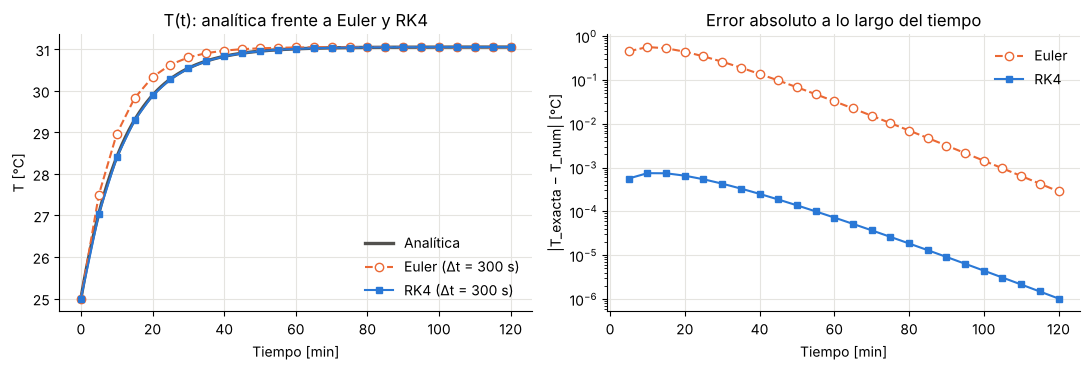

In [5]:
T0_val, tf_val = 25.0, 2*3600.0
u_c, Ta_c = (lambda t: 1.0), (lambda t: Ta_cte)
T_exacta = lambda t: analitica(t, T0_val, Tss_cl, tau_cl)

dt_demo = 300.0
te, Te = euler(dTdt, 0, tf_val, T0_val, dt_demo, p0, u_c, Ta_c)
tr, Tr = rk4(dTdt, 0, tf_val, T0_val, dt_demo, p0, u_c, Ta_c)
tf_ = np.linspace(0, tf_val, 600)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(tf_/60, T_exacta(tf_), color=GRIS, lw=2.4, label="Analítica")
a1.plot(te/60, Te, "o--", color=C2, mfc="white", label="Euler (Δt = 300 s)")
a1.plot(tr/60, Tr, "s-", color=C1, ms=4, label="RK4 (Δt = 300 s)")
a1.set_xlabel("Tiempo [min]"); a1.set_ylabel("T [°C]"); a1.legend(frameon=False)
a1.set_title("T(t): analítica frente a Euler y RK4")
a2.semilogy(te[1:]/60, np.abs(Te - T_exacta(te))[1:], "o--", color=C2, mfc="white", label="Euler")
a2.semilogy(tr[1:]/60, np.abs(Tr - T_exacta(tr))[1:], "s-", color=C1, ms=4, label="RK4")
a2.set_xlabel("Tiempo [min]"); a2.set_ylabel("|T_exacta − T_num| [°C]"); a2.legend(frameon=False)
a2.set_title("Error absoluto a lo largo del tiempo")
fig.tight_layout(); plt.show()

print(f"Error máximo con Δt = 300 s -> Euler: {np.max(np.abs(Te - T_exacta(te))):.3e} °C | "
      f"RK4: {np.max(np.abs(Tr - T_exacta(tr))):.3e} °C")

## 5. Errores absoluto y relativo para distintos pasos

Para cada $\Delta t$ se calcula el error máximo sobre toda la trayectoria:

$$E_{abs} = \max_n |T_{exacta}(t_n) - T_n|, \qquad E_{rel} = \max_n \frac{|T_{exacta}(t_n) - T_n|}{|T_{exacta}(t_n)|}$$

In [6]:
pasos = [600.0, 300.0, 120.0, 60.0, 30.0, 10.0, 5.0]
filas = []
for dt in pasos:
    te, Te = euler(dTdt, 0, tf_val, T0_val, dt, p0, u_c, Ta_c)
    tr, Tr = rk4(dTdt, 0, tf_val, T0_val, dt, p0, u_c, Ta_c)
    xe, xr = T_exacta(te), T_exacta(tr)
    filas.append([dt, np.max(np.abs(Te - xe)), np.max(np.abs(Te - xe)/np.abs(xe)),
                      np.max(np.abs(Tr - xr)), np.max(np.abs(Tr - xr)/np.abs(xr))])
tabla_err = pd.DataFrame(filas, columns=["Δt [s]", "E_abs Euler [°C]", "E_rel Euler",
                                         "E_abs RK4 [°C]", "E_rel RK4"])
tabla_err

,Δt [s],E_abs Euler [°C],E_rel Euler,E_abs RK4 [°C],E_rel RK4
0,600,1.594,0.05612,0.01691,0.0005956
1,300,0.5635,0.01984,0.0007461,2.627e-05
2,120,0.1976,0.00689,1.579e-05,5.481e-07
3,60,0.09519,0.003318,9.211e-07,3.205e-08
4,30,0.04675,0.001628,5.562e-08,1.935e-09
5,10,0.0154,0.0005361,6.711e-10,2.335e-11
6,5,0.007679,0.0002672,4.17e-11,1.451e-12


## 6. Orden de convergencia

Si el error se comporta como $E \approx K\,\Delta t^{p}$, entonces $\log E = \log K + p\log\Delta t$: el **orden $p$ es la pendiente** de la recta en escala log-log. Se obtiene por mínimos cuadrados (`np.polyfit`) y también entre pares de pasos consecutivos, $p_i = \dfrac{\ln(E_i/E_{i+1})}{\ln(\Delta t_i/\Delta t_{i+1})}$.

Orden observado (ajuste global): Euler = 1.09 (teórico 1) | RK4 = 4.12 (teórico 4)


,Entre Δt [s],Orden local Euler,Orden local RK4
0,600 → 300,1.5,4.503
1,300 → 120,1.144,4.208
2,120 → 60,1.054,4.099
3,60 → 30,1.026,4.05
4,30 → 10,1.011,4.021
5,10 → 5,1.004,4.008


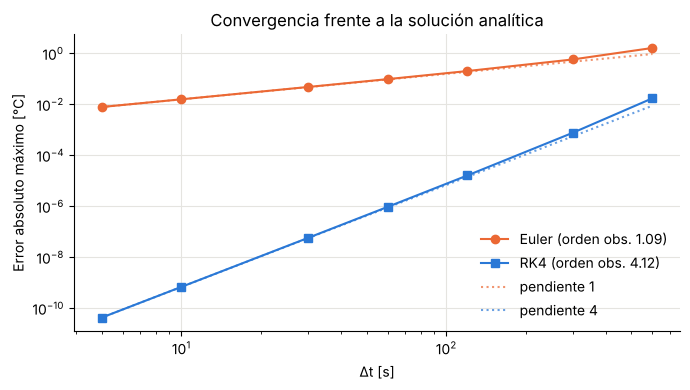

In [7]:
dts = tabla_err["Δt [s]"].values
eE, eR = tabla_err["E_abs Euler [°C]"].values, tabla_err["E_abs RK4 [°C]"].values
ordE = np.polyfit(np.log(dts), np.log(eE), 1)[0]
ordR = np.polyfit(np.log(dts), np.log(eR), 1)[0]
print(f"Orden observado (ajuste global): Euler = {ordE:.2f} (teórico 1) | RK4 = {ordR:.2f} (teórico 4)")

orden_local = pd.DataFrame({
    "Entre Δt [s]": [f"{dts[i]:.0f} → {dts[i+1]:.0f}" for i in range(len(dts)-1)],
    "Orden local Euler": [np.log(eE[i]/eE[i+1]) / np.log(dts[i]/dts[i+1]) for i in range(len(dts)-1)],
    "Orden local RK4":   [np.log(eR[i]/eR[i+1]) / np.log(dts[i]/dts[i+1]) for i in range(len(dts)-1)],
})
display(orden_local)

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(dts, eE, "o-", color=C2, label=f"Euler (orden obs. {ordE:.2f})")
ax.loglog(dts, eR, "s-", color=C1, label=f"RK4 (orden obs. {ordR:.2f})")
g = np.array([dts.min(), dts.max()])
ax.loglog(g, eE[-1]*(g/dts[-1])**1, ":", color=C2, alpha=0.7, label="pendiente 1")
ax.loglog(g, eR[-1]*(g/dts[-1])**4, ":", color=C1, alpha=0.7, label="pendiente 4")
ax.set_xlabel("Δt [s]"); ax.set_ylabel("Error absoluto máximo [°C]")
ax.set_title("Convergencia frente a la solución analítica"); ax.legend(frameon=False)
fig.tight_layout(); plt.show()

## 7. Estabilidad de Euler

En la región lineal, $f(T) = -\lambda\,(T - T_{ss})$ con $\lambda = (hA + K_p)/C$. Euler da $T_{n+1} - T_{ss} = g\,(T_n - T_{ss})$ con **factor de amplificación** $g = 1 - \lambda\,\Delta t$. El método es estable si $|g| < 1$, es decir:

$$\Delta t < \frac{2}{\lambda} = \frac{2C}{hA + K_p}$$

Para $\Delta t$ por debajo del límite la oscilación se amortigua; por encima, crece hasta que la saturación del control la limita, y la solución numérica deja de tener sentido físico. RK4 tiene una región de estabilidad mayor ($|\lambda\Delta t| \lesssim 2{,}79$).

λ = 1.375e-03 1/s  ->  Δt crítico de Euler = 2C/(hA+Kp) = 1455 s


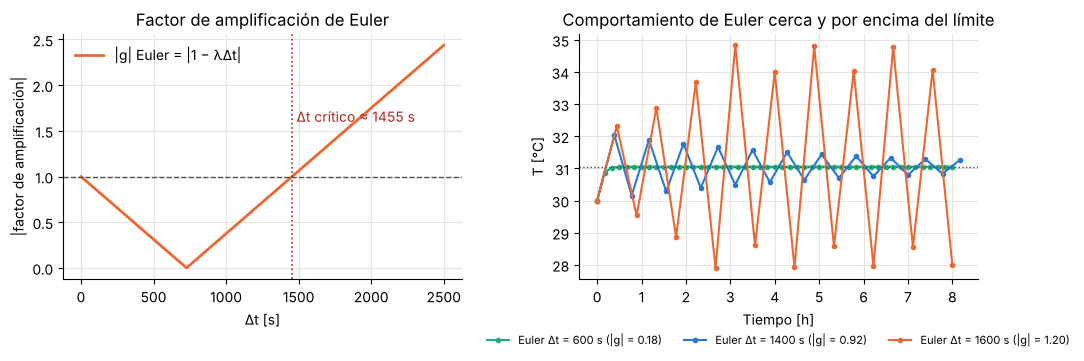

In [8]:
lam = (p0.hA + p0.Kp) / p0.C
dt_crit = 2 / lam
print(f"λ = {lam:.3e} 1/s  ->  Δt crítico de Euler = 2C/(hA+Kp) = {dt_crit:.0f} s")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
dtv = np.linspace(1, 2500, 400)
a1.plot(dtv, np.abs(1 - lam*dtv), color=C2, lw=2, label="|g| Euler = |1 − λΔt|")
a1.axhline(1, color=GRIS, ls="--", lw=1); a1.axvline(dt_crit, color=CRIT, ls=":", lw=1.2)
a1.text(dt_crit + 30, 1.6, f"Δt crítico ≈ {dt_crit:.0f} s", color=CRIT)
a1.set_xlabel("Δt [s]"); a1.set_ylabel("|factor de amplificación|"); a1.legend(frameon=False)
a1.set_title("Factor de amplificación de Euler")

T0_est = 30.0   # cerca del equilibrio y sin saturar el control
for dt, col in [(600, C3), (1400, C1), (1600, C2)]:
    t_, T_ = euler(dTdt, 0, 8*3600, T0_est, dt, p0, u_c, Ta_c)
    a2.plot(t_/3600, T_, "o-", ms=3, color=col, label=f"Euler Δt = {dt} s (|g| = {abs(1-lam*dt):.2f})")
a2.axhline(Tss_cl, color=GRIS, ls=":", lw=1)
a2.set_xlabel("Tiempo [h]"); a2.set_ylabel("T [°C]"); a2.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
a2.set_title("Comportamiento de Euler cerca y por encima del límite")
fig.tight_layout(); plt.show()

## 8. Costo computacional frente a precisión

Euler evalúa $f$ **una vez** por paso y RK4 **cuatro veces**. Para comparar con justicia se grafica el error contra el número total de evaluaciones de $f$ (y se mide el tiempo de cómputo). Esto justifica elegir RK4 como método de producción.

RK4 con Δt = 300 s (96 evaluaciones) ya tiene error 7.5e-04 °C; Euler necesita más de 1440 evaluaciones y aún tiene 7.7e-03 °C.


,Δt [s],Evaluaciones f Euler,Evaluaciones f RK4,Tiempo Euler [ms],Tiempo RK4 [ms]
0,600,12,48,0.1575,0.3552
1,300,24,96,0.2076,0.6046
2,120,60,240,0.3564,1.469
3,60,120,480,0.7682,2.992
4,30,240,960,1.483,5.993
5,10,720,2880,4.636,20.63
6,5,1440,5760,8.946,35.96


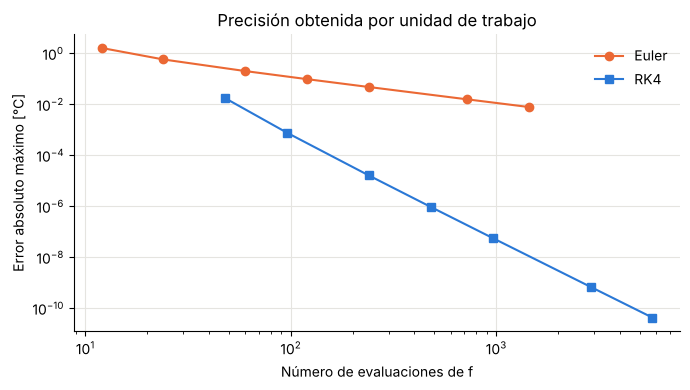

In [9]:
filas = []
for dt in pasos:
    n = int(round(tf_val / dt))
    t1 = time.perf_counter(); euler(dTdt, 0, tf_val, T0_val, dt, p0, u_c, Ta_c); tE = time.perf_counter() - t1
    t1 = time.perf_counter(); rk4(dTdt, 0, tf_val, T0_val, dt, p0, u_c, Ta_c);   tR = time.perf_counter() - t1
    filas.append([dt, n, 4*n, tE*1e3, tR*1e3])
costo = pd.DataFrame(filas, columns=["Δt [s]", "Evaluaciones f Euler", "Evaluaciones f RK4",
                                     "Tiempo Euler [ms]", "Tiempo RK4 [ms]"])
display(costo)

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(costo["Evaluaciones f Euler"], eE, "o-", color=C2, label="Euler")
ax.loglog(costo["Evaluaciones f RK4"], eR, "s-", color=C1, label="RK4")
ax.set_xlabel("Número de evaluaciones de f"); ax.set_ylabel("Error absoluto máximo [°C]")
ax.set_title("Precisión obtenida por unidad de trabajo"); ax.legend(frameon=False)
fig.tight_layout(); plt.show()

i_e = np.argmin(np.abs(eE - eR[1]))
print(f"RK4 con Δt = 300 s ({int(costo['Evaluaciones f RK4'][1])} evaluaciones) ya tiene error {eR[1]:.1e} °C; "
      f"Euler necesita más de {int(costo['Evaluaciones f Euler'].iloc[-1])} evaluaciones y aún tiene {eE[-1]:.1e} °C.")

## 9. Caso general sin solución analítica

En la operación real la carga $u(t)$ y el clima $T_a(t)$ varían, y el control puede saturarse: la EDO es no lineal y **no tiene solución analítica**. Para validar se construye una **solución de referencia** con RK4 y un paso 20 veces menor ($\Delta t = 0{,}5$ s) y se compara con los pasos de producción. Se usa el escenario E3 (pico de tokens, clima cálido, aire). *Esta celda tarda unos segundos.*

Método,EULER,RK4
Δt [s],,
10,0.01719,8.148e-06
30,0.05183,0.0001953
60,0.1049,0.0002787
120,0.2174,0.002186


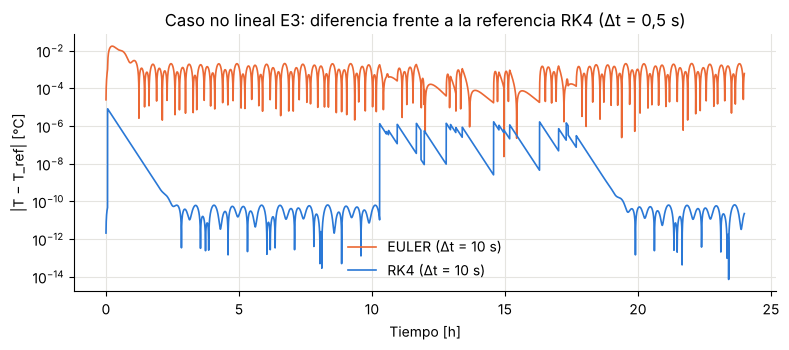

In [10]:
p3 = Params(estrategia="aire")
u3, Ta3 = perfil_carga(0.85), perfil_Ta(32.0, 4.0)
ref = simular(p3, u3, Ta3, T0=22.0, tf=24*3600, dt=0.5, metodo="rk4")

filas, curvas = [], {}
for dt in [120.0, 60.0, 30.0, 10.0]:
    for m in ["euler", "rk4"]:
        s = simular(p3, u3, Ta3, T0=22.0, tf=24*3600, dt=dt, metodo=m)
        idx = np.searchsorted(ref["t"], s["t"])
        d = np.abs(s["T"] - ref["T"][idx])
        filas.append([m.upper(), dt, d.max()])
        if dt == 10.0: curvas[m] = (s["t"], d)
tabla_ref = pd.DataFrame(filas, columns=["Método", "Δt [s]", "Diferencia máx. vs referencia [°C]"])
display(tabla_ref.pivot(index="Δt [s]", columns="Método", values="Diferencia máx. vs referencia [°C]"))

fig, ax = plt.subplots(figsize=(8, 3.6))
for m, col in [("euler", C2), ("rk4", C1)]:
    t_, d_ = curvas[m]
    ax.semilogy(t_[1:]/3600, d_[1:] + 1e-16, color=col, lw=1.2, label=f"{m.upper()} (Δt = 10 s)")
ax.set_xlabel("Tiempo [h]"); ax.set_ylabel("|T − T_ref| [°C]")
ax.set_title("Caso no lineal E3: diferencia frente a la referencia RK4 (Δt = 0,5 s)")
ax.legend(frameon=False); fig.tight_layout(); plt.show()

## 10. Escenarios E1–E5 y conservación de la energía

Cinco escenarios de 24 h con RK4 ($\Delta t = 10$ s, $T_0 = 22$ °C). Para cada uno se verifica el **principio de conservación de la energía**:

$$\int P_s\,dt = C\,\Delta T + \int hA\,(T - T_a)\,dt + \int Q_{ref}\,dt + \varepsilon$$

Un residuo relativo $|\varepsilon|/\int P_s\,dt \ll 1$ confirma que la integración numérica respeta la física.

In [11]:
escenarios = {
    "E1": dict(u=0.40, Ta=20.0, A=5.0, estrategia="aire"),
    "E2": dict(u=0.85, Ta=20.0, A=5.0, estrategia="aire"),
    "E3": dict(u=0.85, Ta=32.0, A=4.0, estrategia="aire"),
    "E4": dict(u=0.85, Ta=32.0, A=4.0, estrategia="liquida"),
    "E5": dict(u=0.85, Ta=32.0, A=4.0, estrategia="liquida", Kp=6000.0, T_set=22.0),
}
kWh = 1/3.6e6
res, filas = {}, []
for k, e in escenarios.items():
    p = Params(estrategia=e["estrategia"], Kp=e.get("Kp", 2500.0), T_set=e.get("T_set", 24.0))
    s = simular(p, perfil_carga(e["u"]), perfil_Ta(e["Ta"], e["A"]), T0=22.0, tf=24*3600, dt=10.0)
    res[k] = s; b = s["balance"]
    filas.append([k, s["T"].max(), trapezoid(s["P_tot"], s["t"])/trapezoid(s["Ps"], s["t"]),
                  s["E_IT"][-1]*kWh, s["E_cool"][-1]*kWh, s["E_tot"][-1]*kWh,
                  100*s["frac_critica"], b["E_in"]*kWh, b["dU"]*kWh, b["E_env"]*kWh,
                  b["E_ref"]*kWh, b["residuo_rel"]])
tabla_esc = pd.DataFrame(filas, columns=["Esc.", "T_max [°C]", "PUE medio", "E_TI [kWh]",
    "E_ref [kWh]", "E_total [kWh]", "% t > 32 °C", "∫P_s dt [kWh]", "C·ΔT [kWh]",
    "∫hA(T−T_a) dt [kWh]", "∫Q_ref dt [kWh]", "Residuo relativo"])
tabla_esc

,Esc.,T_max [°C],PUE medio,E_TI [kWh],E_ref [kWh],E_total [kWh],% t > 32 °C,∫P_s dt [kWh],C·ΔT [kWh],∫hA(T−T_a) dt [kWh],∫Q_ref dt [kWh],Residuo relativo
0,E1,29.7,1.297,284.1,59.95,368.5,0,284.1,2.693,47.37,234,4.403e-08
1,E2,31.5,1.273,434.5,93.95,552.9,0,434.5,3.991,60.94,369.6,7.186e-08
2,E3,32.5,1.39,434.5,145.1,604.1,34.26,434.5,4.631,-4.572,434.4,7.253e-09
3,E4,32.5,1.213,434.5,68.12,527.1,34.26,434.5,4.631,-4.572,434.4,7.253e-09
4,E5,25.82,1.227,434.5,74.17,533.1,0,434.5,1.616,-40.28,473.2,3e-07


Líquida vs aire (E3→E4): −53.1 % energía de refrigeración, −77 kWh/día
Calibración óptima (E3→E5): −11.7 % energía total
Residuo relativo máximo del balance: 3.0e-07


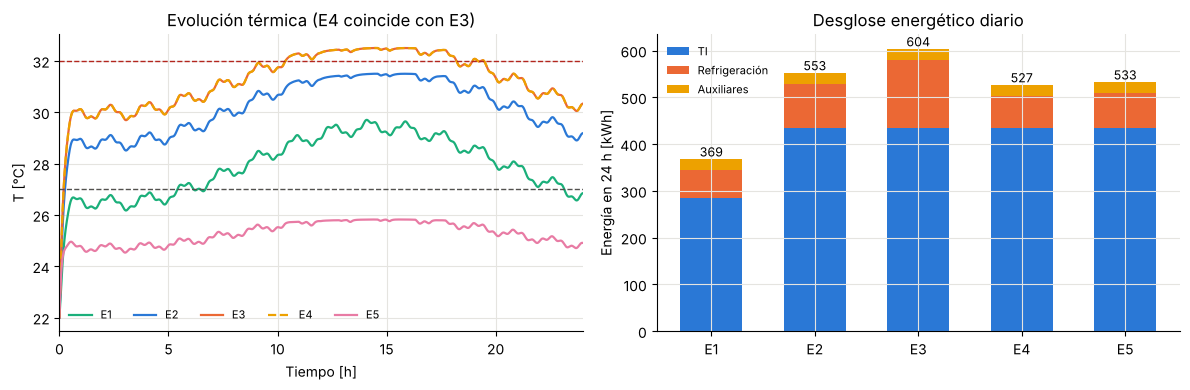

In [12]:
cols = {"E1": C3, "E2": C1, "E3": C2, "E4": C4, "E5": C5}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for k, s in res.items():
    a1.plot(s["t"]/3600, s["T"], color=cols[k], lw=1.6, ls="--" if k == "E4" else "-", label=k)
a1.axhline(27, color=GRIS, ls="--", lw=1); a1.axhline(32, color=CRIT, ls="--", lw=1)
a1.set_xlabel("Tiempo [h]"); a1.set_ylabel("T [°C]"); a1.set_xlim(0, 24)
a1.set_title("Evolución térmica (E4 coincide con E3)"); a1.legend(frameon=False, ncol=5, fontsize=8)

ks = list(res); x = np.arange(len(ks))
eIT = tabla_esc["E_TI [kWh]"].values; eCo = tabla_esc["E_ref [kWh]"].values
eAux = tabla_esc["E_total [kWh]"].values - eIT - eCo
a2.bar(x, eIT, 0.6, color=C1, label="TI"); a2.bar(x, eCo, 0.6, bottom=eIT, color=C2, label="Refrigeración")
a2.bar(x, eAux, 0.6, bottom=eIT + eCo, color=C4, label="Auxiliares")
for i, tot in enumerate(tabla_esc["E_total [kWh]"]): a2.text(i, tot + 5, f"{tot:.0f}", ha="center", fontsize=9)
a2.set_xticks(x); a2.set_xticklabels(ks); a2.set_ylabel("Energía en 24 h [kWh]")
a2.set_title("Desglose energético diario"); a2.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

E = tabla_esc.set_index("Esc.")
print(f"Líquida vs aire (E3→E4): −{100*(1 - E.loc['E4','E_ref [kWh]']/E.loc['E3','E_ref [kWh]']):.1f} % energía de refrigeración, "
      f"−{E.loc['E3','E_total [kWh]'] - E.loc['E4','E_total [kWh]']:.0f} kWh/día")
print(f"Calibración óptima (E3→E5): −{100*(1 - E.loc['E5','E_total [kWh]']/E.loc['E3','E_total [kWh]']):.1f} % energía total")
print(f"Residuo relativo máximo del balance: {E['Residuo relativo'].max():.1e}")

## 11. Sensibilidad paramétrica

Sensibilidad de la temperatura estacionaria de lazo cerrado frente a cada parámetro $\alpha$: $S_\alpha = \partial T_{ss}/\partial\alpha$. Derivando la expresión analítica:

$$S_{P_s} = \frac{1}{hA+K_p},\quad S_{K_p} = \frac{T_{set}-T_{ss}}{hA+K_p},\quad S_{hA} = \frac{T_a-T_{ss}}{hA+K_p},\quad S_{T_{set}} = \frac{K_p}{hA+K_p},\quad S_{T_a} = \frac{hA}{hA+K_p}$$

Se comparan con una **derivada numérica por diferencias centradas** ($\pm 1\,\%$ del parámetro) sobre simulaciones RK4.

,Parámetro,Valor nominal,S analítica,S numérica (RK4),Diferencia [%],ΔT_ss para +10 % [°C]
0,P_s,2.04e+04,0.0003636,0.0003636,1.743e-10,0.7418
1,K_p,2500,-0.002565,-0.002566,0.008265,-0.6413
2,hA,250,-0.00402,-0.00402,8.264e-05,-0.1005
3,T_set,24,0.9091,0.9091,1.227e-10,2.182
4,T_a,20,0.09091,0.09091,6.967e-10,0.1818


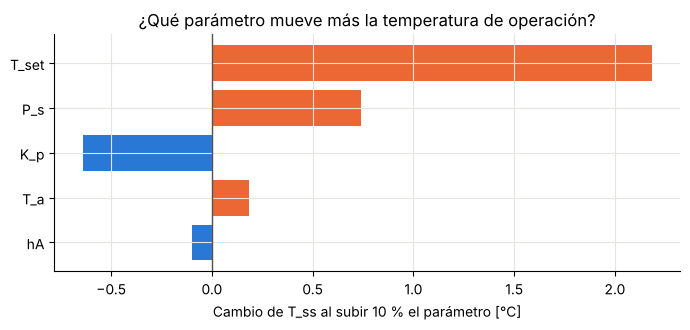

In [13]:
k_ = p0.hA + p0.Kp
analiticas = {"P_s": 1/k_, "K_p": (p0.T_set - Tss_cl)/k_, "hA": (Ta_cte - Tss_cl)/k_,
              "T_set": p0.Kp/k_, "T_a": p0.hA/k_}
nominal = {"P_s": Ps_pico, "K_p": p0.Kp, "hA": p0.hA, "T_set": p0.T_set, "T_a": Ta_cte}

def T_estacionaria(nombre, valor):
    # Simula con RK4 hasta el estado estacionario cambiando un solo parámetro
    p, Ta = Params(), Ta_cte
    if nombre == "P_s": p.P_nodo_max = valor / p.N_serv   # con u = 1, P_s = N·P_max
    elif nombre == "K_p": p.Kp = valor
    elif nombre == "hA": p.hA = valor
    elif nombre == "T_set": p.T_set = valor
    else: Ta = valor
    _, T = rk4(dTdt, 0, 20000, Tss_cl, 10.0, p, lambda t: 1.0, lambda t: Ta)
    return T[-1]

filas = []
for nom, v in nominal.items():
    d = 0.01 * v
    num = (T_estacionaria(nom, v + d) - T_estacionaria(nom, v - d)) / (2*d)
    filas.append([nom, v, analiticas[nom], num, abs(num - analiticas[nom])/abs(analiticas[nom])*100,
                  analiticas[nom]*0.1*v])
sens = pd.DataFrame(filas, columns=["Parámetro", "Valor nominal", "S analítica", "S numérica (RK4)",
                                    "Diferencia [%]", "ΔT_ss para +10 % [°C]"])
display(sens)

fig, ax = plt.subplots(figsize=(7, 3.4))
orden = sens.reindex(sens["ΔT_ss para +10 % [°C]"].abs().sort_values().index)
ax.barh(orden["Parámetro"], orden["ΔT_ss para +10 % [°C]"],
        color=[C2 if v > 0 else C1 for v in orden["ΔT_ss para +10 % [°C]"]])
ax.axvline(0, color=GRIS, lw=1)
ax.set_xlabel("Cambio de T_ss al subir 10 % el parámetro [°C]")
ax.set_title("¿Qué parámetro mueve más la temperatura de operación?")
fig.tight_layout(); plt.show()

## 12. Comparación teórico–numérica

En cuatro puntos de operación constantes (control no saturado) se compara el estado estacionario y la constante de tiempo de la ecuación analítica con los obtenidos por RK4. El error porcentual es

$$\varepsilon(\%) = \frac{|x_{teórico} - x_{numérico}|}{|x_{teórico}|}\times 100$$

$T_{ss}$ numérica: valor de RK4 ($\Delta t = 10$ s) tras 20 000 s. $\tau_{cl}$ numérica: instante en que RK4 ($\Delta t = 1$ s) recorre el 63,2 % del cambio, interpolando entre pasos.

In [14]:
filas = []
for u, Ta in [(0.3, 20.0), (0.6, 20.0), (1.0, 20.0), (1.0, 32.0)]:
    Ps = P_IT(u, p0)
    Tss_t = (Ps + p0.hA*Ta + p0.Kp*p0.T_set)/(p0.hA + p0.Kp)
    _, T = rk4(dTdt, 0, 20000, 25.0, 10.0, p0, lambda t, u=u: u, lambda t, Ta=Ta: Ta)
    t1, T1 = rk4(dTdt, 0, 3000, 25.0, 1.0, p0, lambda t, u=u: u, lambda t, Ta=Ta: Ta)
    obj = 25.0 + (Tss_t - 25.0)*(1 - np.exp(-1))
    i = np.argmax((T1 - obj)*np.sign(Tss_t - 25.0) >= 0)
    tau_num = t1[i-1] + (obj - T1[i-1])/(T1[i] - T1[i-1])*(t1[i] - t1[i-1])
    filas.append([f"u={u}, T_a={Ta:.0f} °C", Ps/1e3, Tss_t, T[-1], abs(T[-1] - Tss_t)/Tss_t*100,
                  tau_cl, tau_num, abs(tau_num - tau_cl)/tau_cl*100])
teo_num = pd.DataFrame(filas, columns=["Caso", "P_s [kW]", "T_ss teórica [°C]", "T_ss RK4 [°C]",
                                       "ε_T [%]", "τ teórica [s]", "τ RK4 [s]", "ε_τ [%]"])
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
display(teo_num)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

,Caso,P_s [kW],T_ss teórica [°C],T_ss RK4 [°C],ε_T [%],τ teórica [s],τ RK4 [s],ε_τ [%]
0,"u=0.3, T_a=20 °C",10.4,27.42,27.42,1.005e-11,727.3,727.3,1.875e-05
1,"u=0.6, T_a=20 °C",14.69,28.98,28.98,1.563e-11,727.3,727.3,1.875e-05
2,"u=1.0, T_a=20 °C",20.4,31.05,31.05,2.223e-11,727.3,727.3,1.875e-05
3,"u=1.0, T_a=32 °C",20.4,32.15,32.15,2.538e-11,727.3,727.3,1.875e-05


## 13. Conclusiones del análisis numérico

1. **Validación:** con la solución analítica como patrón, RK4 reproduce la trayectoria exacta incluso con pasos gruesos, mientras Euler muestra el error característico de orden 1.
2. **Convergencia:** los órdenes observados (≈ 1 para Euler y ≈ 4 para RK4) coinciden con la teoría, lo que confirma que ambos métodos están bien implementados.
3. **Estabilidad:** Euler es inestable para $\Delta t > 2C/(hA+K_p) \approx 1455$ s; el paso de producción (10 s) está muy por debajo.
4. **Eficiencia:** por unidad de trabajo (evaluaciones de $f$) RK4 alcanza errores varios órdenes de magnitud menores que Euler; por eso es el método de producción.
5. **Caso no lineal:** sin solución analítica, la comparación con una referencia RK4 de paso 0,5 s muestra que el paso de 10 s es más que suficiente.
6. **Física:** el balance de energía se cierra con residuos del orden de $10^{-7}$ en todos los escenarios, y la teoría y la simulación coinciden con $\varepsilon < 10^{-4}\,\%$.